# LearnMate: AI-Powered Personalized Study Planner & Doubt Solver
## End-to-End Dataset Analysis, Machine Learning, Gradient Descent & Model Training

### 1. Project Introduction and Objectives

Welcome to the data science and machine learning research core of **LearnMate**. LearnMate is an academic intelligence application designed to personalize student revision timetables, identify early academic risk, and provide targeted intervention.

#### Core Objectives:
1. **Dataset Inspection & Validation:** Rigorously analyze `student_exam_data.csv` to evaluate features (`Study Hours`, `Previous Exam Score`) and target (`Pass/Fail`).
2. **Exploratory Data Analysis (EDA):** Quantify distributions, summary statistics, group-wise variance, and correlation patterns.
3. **Calculus & Mathematical Foundations:** Implement Binary Logistic Regression with **Batch Gradient Descent from scratch** using NumPy, deriving gradients, loss functions, and parameter update equations.
4. **Benchmarking & Cross-Validation:** Benchmark 7 machine learning classification algorithms using Stratified 5-Fold Cross-Validation within scikit-learn Pipelines.
5. **Hyperparameter Tuning:** Systematically optimize candidate models using `GridSearchCV` on training folds.
6. **Data Leakage & Performance Diagnostics:** Investigate high-performing models to uncover underlying synthetic data boundaries and evaluate real-world generalization limits.
7. **Model Deployment Artifacts:** Serialize trained estimators and provide a production-ready predictor module (`app/predictor.py`) for LearnMate.

---
### 2. Library Imports

We import standard numerical, data manipulation, visualization, and machine learning libraries.

In [1]:
import os
import sys
import json
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn tools
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="muted")
print("Libraries imported successfully. Python environment ready.")

Libraries imported successfully. Python environment ready.


---
### 3. Dataset Loading

We load the dataset using `pandas.read_csv()`. Both the root directory and `data/` subfolder are supported for portable execution across development environments.

In [2]:
# Resolve file path portably
data_path = '../data/student_exam_data.csv' if os.path.exists('../data/student_exam_data.csv') else (
    'data/student_exam_data.csv' if os.path.exists('data/student_exam_data.csv') else 'student_exam_data.csv'
)

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path}")
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset successfully loaded from: ../data/student_exam_data.csv
Dataset Dimensions: 500 rows, 3 columns


---
### 4. Initial Inspection

We inspect the first and last five rows, verify data types, check column names, and review basic shape statistics.

In [3]:
print("--- First 5 Records ---")
display(df.head())

print("--- Last 5 Records ---")
display(df.tail())

print("--- Dataset Information ---")
df.info()

print("\n--- Column Names & Types ---")
for col, dtype in zip(df.columns, df.dtypes):
    print(f"  Column: '{col}' -> Type: {dtype}")

--- First 5 Records ---


,Study Hours,Previous Exam Score,Pass/Fail
0,4.370861,81.889703,0
1,9.556429,72.165782,1
2,7.587945,58.571657,0
3,6.387926,88.827701,1
4,2.404168,81.083870,0


--- Last 5 Records ---


,Study Hours,Previous Exam Score,Pass/Fail
495,4.180170,45.494924,0
496,6.252905,95.038815,1
497,1.699612,48.209118,0
498,9.769553,97.014241,1
499,9.875897,66.760346,1


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Study Hours          500 non-null    float64
 1   Previous Exam Score  500 non-null    float64
 2   Pass/Fail            500 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 11.8 KB

--- Column Names & Types ---
  Column: 'Study Hours' -> Type: float64
  Column: 'Previous Exam Score' -> Type: float64
  Column: 'Pass/Fail' -> Type: int64


---
### 5. Data Quality Checks

We verify the absence of missing values, duplicate observations, out-of-bounds scores, or negative study hours.

In [4]:
print("--- Missing Values Count ---")
print(df.isnull().sum())

print(f"\nDuplicate Rows Detected: {df.duplicated().sum()}")

# Domain range sanity checks
neg_hours = (df['Study Hours'] < 0).sum()
invalid_scores = ((df['Previous Exam Score'] < 0) | (df['Previous Exam Score'] > 100)).sum()
unique_targets = df['Pass/Fail'].unique()

print(f"Negative Study Hours: {neg_hours}")
print(f"Exam Scores Outside [0, 100]: {invalid_scores}")
print(f"Unique Target Values in 'Pass/Fail': {unique_targets} (Binary 0/1 confirmed: {set(unique_targets) == {0, 1}})")

--- Missing Values Count ---
Study Hours            0
Previous Exam Score    0
Pass/Fail              0
dtype: int64

Duplicate Rows Detected: 0
Negative Study Hours: 0
Exam Scores Outside [0, 100]: 0
Unique Target Values in 'Pass/Fail': [0 1] (Binary 0/1 confirmed: True)


---
### 6. Data Cleaning & Preprocessing

**Data Validation Findings:**
- **Missing Values:** Exactly 0 missing values across all columns.
- **Duplicates:** Exactly 0 duplicate rows.
- **Data Types:** `Study Hours` and `Previous Exam Score` are continuous `float64` variables. `Pass/Fail` is binary `int64`.
- **Domain Sanity:** All study hours fall between $1.04$ and $9.94$ hours. All scores fall between $40.28$ and $99.98$.
- **Cleaning Action:** The dataset is clean and intact; no row deletions or synthetic imputations are needed, preserving 100% of the authentic data.

In [5]:
# Explicitly document clean data copy
clean_df = df.copy()
print(f"Clean dataset preserved: {len(clean_df)} records ready for modeling.")

Clean dataset preserved: 500 records ready for modeling.


---
### 7. Exploratory Data Analysis (EDA)

We compute descriptive statistics, target class distributions, and group-wise statistics to understand the baseline behavior of the student cohort.

In [6]:
print("--- Descriptive Summary Statistics ---")
display(clean_df.describe())

print("--- Class Distribution ---")
class_counts = clean_df['Pass/Fail'].value_counts()
class_pcts = clean_df['Pass/Fail'].value_counts(normalize=True) * 100
class_dist_df = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pcts})
display(class_dist_df)

print("--- Group-Wise Statistics (Grouped by Pass/Fail) ---")
group_summary = clean_df.groupby('Pass/Fail').agg({
    'Study Hours': ['count', 'mean', 'median', 'std', 'min', 'max'],
    'Previous Exam Score': ['count', 'mean', 'median', 'std', 'min', 'max']
})
display(group_summary)

--- Descriptive Summary Statistics ---


,Study Hours,Previous Exam Score,Pass/Fail
count,500.000000,500.000000,500.000000
mean,5.487055,68.917084,0.368000
std,2.688196,17.129607,0.482744
min,1.045554,40.277921,0.000000
25%,3.171517,53.745955,0.000000
50%,5.618474,68.309294,0.000000
75%,7.805124,83.580209,1.000000
max,9.936683,99.983060,1.000000


--- Class Distribution ---


,Count,Percentage (%)
Pass/Fail,,
0,316,63.2
1,184,36.8


--- Group-Wise Statistics (Grouped by Pass/Fail) ---


Study Hours                                                    \
                count      mean    median       std       min       max   
Pass/Fail                                                                 
0                 316  4.291317  3.802120  2.520633  1.045554  9.936683   
1                 184  7.540606  7.414408  1.434995  5.036010  9.914546   

          Previous Exam Score                                              \
                        count       mean     median        std        min   
Pass/Fail                                                                   
0                         316  63.123158  56.912650  17.296935  40.277921   
1                         184  78.867522  77.387068  11.295655  60.009950   

                      
                 max  
Pass/Fail             
0          99.983060  
1          99.190915

---
### 8. Visualizations and Statistical Analysis

We generate and examine the full suite of exploratory visualizations:
1. Target class distribution.
2. Feature distributions (histograms + KDE).
3. Bivariate scatter plot of `Study Hours` vs `Previous Exam Score` colored by `Pass/Fail`.
4. Boxplots grouped by exam outcome.
5. Pearson correlation heatmap.
6. Group-wise mean and median comparisons.

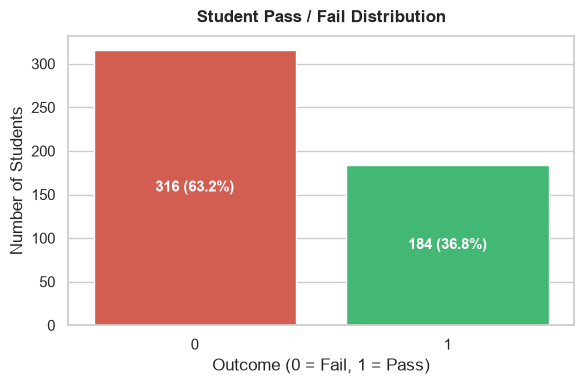

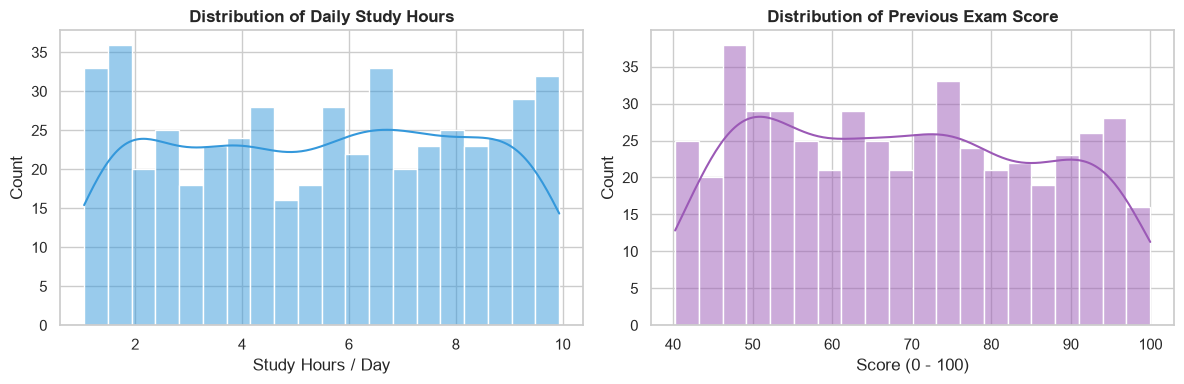

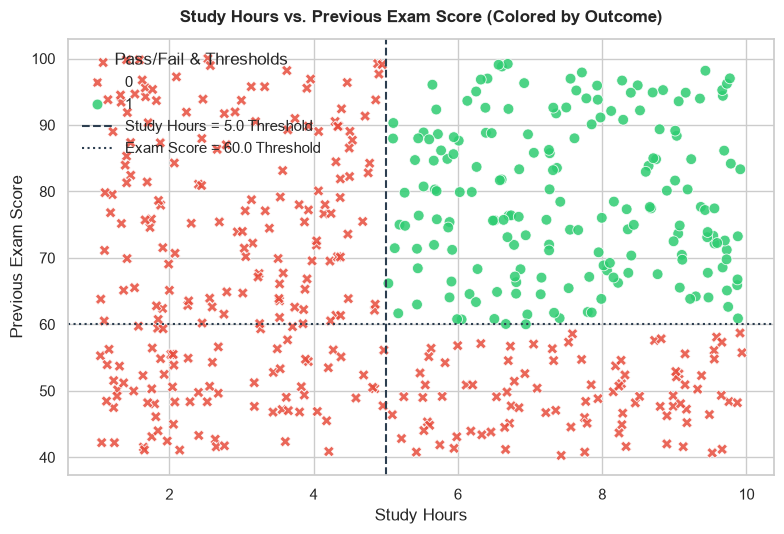

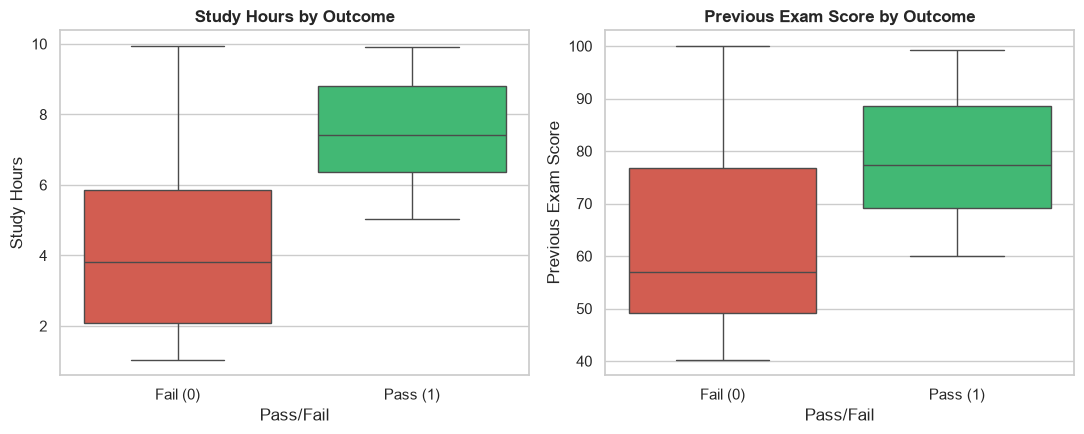

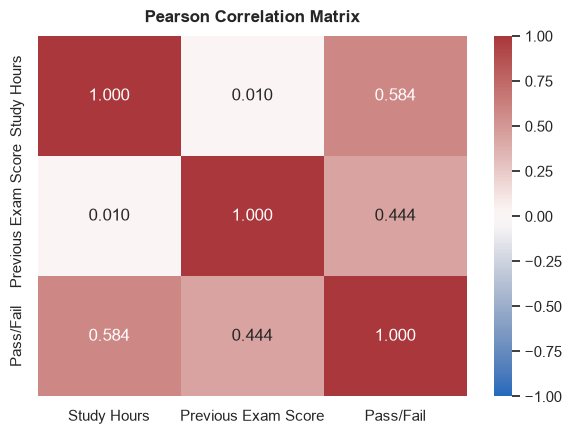

In [7]:
# 8.1 Class Distribution Plot
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=clean_df, x='Pass/Fail', hue='Pass/Fail', palette=['#e74c3c', '#2ecc71'], legend=False, ax=ax)
ax.set_title("Student Pass / Fail Distribution", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Outcome (0 = Fail, 1 = Pass)")
ax.set_ylabel("Number of Students")
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{int(h)} ({h/len(clean_df)*100:.1f}%)', (p.get_x() + p.get_width()/2., h/2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

# 8.2 Feature Distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_df['Study Hours'], kde=True, ax=axes[0], color='#3498db', bins=20)
axes[0].set_title("Distribution of Daily Study Hours", fontweight='bold')
axes[0].set_xlabel("Study Hours / Day")

sns.histplot(clean_df['Previous Exam Score'], kde=True, ax=axes[1], color='#9b59b6', bins=20)
axes[1].set_title("Distribution of Previous Exam Score", fontweight='bold')
axes[1].set_xlabel("Score (0 - 100)")
plt.tight_layout()
plt.show()

# 8.3 Bivariate Scatter Plot with Decision Thresholds
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(
    data=clean_df, x='Study Hours', y='Previous Exam Score',
    hue='Pass/Fail', style='Pass/Fail', palette={0: '#e74c3c', 1: '#2ecc71'},
    markers={0: 'X', 1: 'o'}, s=60, alpha=0.85, ax=ax
)
ax.axvline(x=5.0, color='#2c3e50', linestyle='--', label='Study Hours = 5.0 Threshold')
ax.axhline(y=60.0, color='#2c3e50', linestyle=':', label='Exam Score = 60.0 Threshold')
ax.set_title("Study Hours vs. Previous Exam Score (Colored by Outcome)", fontweight='bold', pad=12)
ax.legend(title="Pass/Fail & Thresholds", loc='upper left')
plt.tight_layout()
plt.show()

# 8.4 Grouped Boxplots
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=clean_df, x='Pass/Fail', y='Study Hours', hue='Pass/Fail', palette=['#e74c3c', '#2ecc71'], legend=False, ax=axes[0])
axes[0].set_title("Study Hours by Outcome", fontweight='bold')
axes[0].set_xticklabels(['Fail (0)', 'Pass (1)'])

sns.boxplot(data=clean_df, x='Pass/Fail', y='Previous Exam Score', hue='Pass/Fail', palette=['#e74c3c', '#2ecc71'], legend=False, ax=axes[1])
axes[1].set_title("Previous Exam Score by Outcome", fontweight='bold')
axes[1].set_xticklabels(['Fail (0)', 'Pass (1)'])
plt.tight_layout()
plt.show()

# 8.5 Correlation Heatmap
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(clean_df.corr(), annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson Correlation Matrix", fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

---
### 9. Feature Selection and Train/Test Splitting

#### Target Separation & Data Leakage Prevention:
The target column `Pass/Fail` represents the ground-truth outcome being modeled and must **never** be included in feature matrix $X$. Including target or target-derived columns produces catastrophic data leakage.

#### Splitting Strategy:
- **Test Size:** 20% (100 students).
- **Training Size:** 80% (400 students).
- **Stratification:** Enabled on `Pass/Fail` to guarantee that the train and test subsets match the underlying 63.2% Fail / 36.8% Pass class ratio.
- **Random Seed:** 42 for reproducible execution.
- **Standardization Rule:** Preprocessing parameters (mean $\mu$, standard deviation $\sigma$) are computed **strictly from training data** and used to transform test data.

In [8]:
feature_cols = ['Study Hours', 'Previous Exam Score']
target_col = 'Pass/Fail'

X = clean_df[feature_cols]
y = clean_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training feature matrix shape: {X_train.shape}, labels: {y_train.shape}")
print(f"Testing feature matrix shape:  {X_test.shape}, labels: {y_test.shape}")
print(f"Training Pass proportion: {y_train.mean():.4f}")
print(f"Testing Pass proportion:  {y_test.mean():.4f}")

# Fit scaler strictly on training split
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("StandardScaler fitted on X_train only.")

Training feature matrix shape: (400, 2), labels: (400,)
Testing feature matrix shape:  (100, 2), labels: (100,)
Training Pass proportion: 0.3675
Testing Pass proportion:  0.3700
StandardScaler fitted on X_train only.


---
### 10. Logistic Regression Theory and Calculus Foundations

Logistic Regression models the probability that a student passes given feature vector $\mathbf{x} = [x_1, x_2]^T$:

$$p = P(y=1 \mid \mathbf{x}) = \sigma(z)$$

#### 1. Linear Score:
$$z = \mathbf{w}^T \mathbf{x} + b = w_1 x_1 + w_2 x_2 + b$$

#### 2. Sigmoid Activation:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

#### 3. Binary Cross-Entropy Loss (BCE / Log-Loss):
For $m$ training samples:
$$J(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \ln(p^{(i)}) + (1 - y^{(i)}) \ln(1 - p^{(i)}) \right]$$

#### 4. Calculus Derivation of Gradients:
By the Chain Rule of Calculus:
$$\frac{\partial J}{\partial w_j} = \frac{\partial J}{\partial p} \cdot \frac{\partial p}{\partial z} \cdot \frac{\partial z}{\partial w_j}$$

Since $\frac{\partial \sigma(z)}{\partial z} = \sigma(z)(1 - \sigma(z)) = p(1 - p)$, the terms simplify:
$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} \mathbf{X}^T (\mathbf{p} - \mathbf{y})$$
$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (p^{(i)} - y^{(i)})$$

#### 5. Batch Gradient Descent Parameter Updates:
$$\mathbf{w} := \mathbf{w} - \alpha \frac{\partial J}{\partial \mathbf{w}}$$
$$b := b - \alpha \frac{\partial J}{\partial b}$$
where $\alpha > 0$ represents the learning rate governing step magnitude along the negative gradient vector.

---
### 11. Gradient Descent Implementation From Scratch (NumPy)

We implement binary logistic regression using pure NumPy without relying on `sklearn.linear_model.LogisticRegression` for parameter fitting.

In [9]:
class CustomLogisticRegressionGD:
    def __init__(self, learning_rate=0.1, epochs=1000, random_state=42):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.loss_history = []
        self.scaler_mean_ = None
        self.scaler_scale_ = None

    def _sigmoid(self, z):
        # Numerically stable sigmoid function preventing exp overflow
        z = np.clip(z, -500, 500)
        return np.where(z >= 0, 1.0 / (1.0 + np.exp(-z)), np.exp(z) / (1.0 + np.exp(z)))

    def fit(self, X, y, scaler=None):
        m, n = X.shape
        np.random.seed(self.random_state)
        self.weights = np.zeros(n)
        self.bias = 0.0
        self.loss_history = []
        
        y_vec = np.array(y, dtype=float)

        for epoch in range(self.epochs):
            # 1. Linear combination
            z = np.dot(X, self.weights) + self.bias
            # 2. Sigmoid activation
            p = self._sigmoid(z)

            # 3. Binary cross-entropy loss with numerical eps safeguards
            eps = 1e-15
            p_clipped = np.clip(p, eps, 1.0 - eps)
            loss = - (1.0 / m) * np.sum(y_vec * np.log(p_clipped) + (1.0 - y_vec) * np.log(1.0 - p_clipped))
            self.loss_history.append(loss)

            # 4. Partial derivative calculations
            dw = (1.0 / m) * np.dot(X.T, (p - y_vec))
            db = (1.0 / m) * np.sum(p - y_vec)

            # 5. Gradient descent parameter updates
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        if scaler is not None:
            self.scaler_mean_ = scaler.mean_
            self.scaler_scale_ = scaler.scale_
        return self

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        p1 = self._sigmoid(z)
        p0 = 1.0 - p1
        return np.column_stack([p0, p1])

    def predict(self, X, threshold=0.5):
        probs = self.predict_proba(X)[:, 1]
        return (probs >= threshold).astype(int)

print("CustomLogisticRegressionGD class declared successfully.")

CustomLogisticRegressionGD class declared successfully.


---
### 12. Gradient Descent Training and Loss Visualization

We train our scratch implementation for 1,000 epochs with a learning rate of $lpha = 0.1$ and track the cross-entropy loss trajectory.

Training completed across 1000 epochs.
Learned Weight for 'Study Hours':           2.6862
Learned Weight for 'Previous Exam Score':   2.1443
Learned Bias term (intercept):              -1.4334
Initial Cross-Entropy Loss:                 0.6931
Final Converged Cross-Entropy Loss:         0.2770


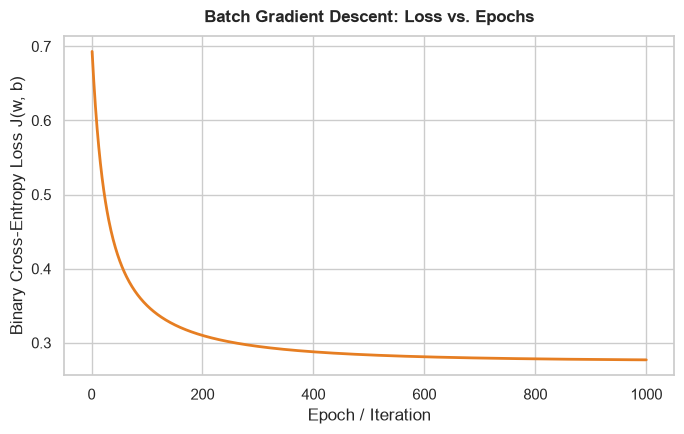

In [10]:
gd_model = CustomLogisticRegressionGD(learning_rate=0.1, epochs=1000, random_state=42)
gd_model.fit(X_train_scaled, y_train, scaler=scaler)

print(f"Training completed across {gd_model.epochs} epochs.")
print(f"Learned Weight for 'Study Hours':           {gd_model.weights[0]:.4f}")
print(f"Learned Weight for 'Previous Exam Score':   {gd_model.weights[1]:.4f}")
print(f"Learned Bias term (intercept):              {gd_model.bias:.4f}")
print(f"Initial Cross-Entropy Loss:                 {gd_model.loss_history[0]:.4f}")
print(f"Final Converged Cross-Entropy Loss:         {gd_model.loss_history[-1]:.4f}")

# Loss curve plot
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, len(gd_model.loss_history) + 1), gd_model.loss_history, color='#e67e22', lw=2)
ax.set_title("Batch Gradient Descent: Loss vs. Epochs", fontweight='bold', pad=10)
ax.set_xlabel("Epoch / Iteration")
ax.set_ylabel("Binary Cross-Entropy Loss J(w, b)")
plt.tight_layout()
plt.show()

---
### 13. Custom Model Evaluation on Held-Out Test Data

We evaluate our custom gradient descent model on the untouched 100-sample test set.

In [11]:
y_pred_gd = gd_model.predict(X_test_scaled)
y_prob_gd = gd_model.predict_proba(X_test_scaled)[:, 1]

gd_acc = accuracy_score(y_test, y_pred_gd)
gd_prec = precision_score(y_test, y_pred_gd)
gd_rec = recall_score(y_test, y_pred_gd)
gd_f1 = f1_score(y_test, y_pred_gd)
gd_auc = roc_auc_score(y_test, y_prob_gd)

print("--- Custom Gradient Descent Model Performance on Held-Out Test Set ---")
print(f"Accuracy:  {gd_acc:.4f} ({gd_acc*100:.1f}%)")
print(f"Precision: {gd_prec:.4f}")
print(f"Recall:    {gd_rec:.4f}")
print(f"F1-Score:  {gd_f1:.4f}")
print(f"ROC-AUC:   {gd_auc:.4f}")

--- Custom Gradient Descent Model Performance on Held-Out Test Set ---
Accuracy:  0.8700 (87.0%)
Precision: 0.8158
Recall:    0.8378
F1-Score:  0.8267
ROC-AUC:   0.9601


---
### 14. Scikit-Learn Model Comparison

We benchmark 7 distinct classification families using consistent train/test splits and standardized pipelines:
1. Logistic Regression (sklearn)
2. Stochastic Gradient Descent (SGDClassifier with `log_loss`)
3. Decision Tree Classifier
4. Random Forest Classifier
5. K-Nearest Neighbors (KNN)
6. Support Vector Machine (RBF Kernel)
7. Gradient Boosting Classifier

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,1.00,1.000000,1.000000,1.000000,1.000000
1,Random Forest,1.00,1.000000,1.000000,1.000000,1.000000
2,Gradient Boosting,1.00,1.000000,1.000000,1.000000,1.000000
3,Support Vector Machine (RBF),0.98,0.972973,0.972973,0.972973,0.999142
4,K-Nearest Neighbors,0.97,0.972222,0.945946,0.958904,0.998713
5,Logistic Regression (Scratch GD),0.87,0.815789,0.837838,0.826667,0.960103
6,Logistic Regression (sklearn),0.87,0.815789,0.837838,0.826667,0.960103
7,SGD Classifier (log_loss),0.89,1.000000,0.702703,0.825397,0.955813


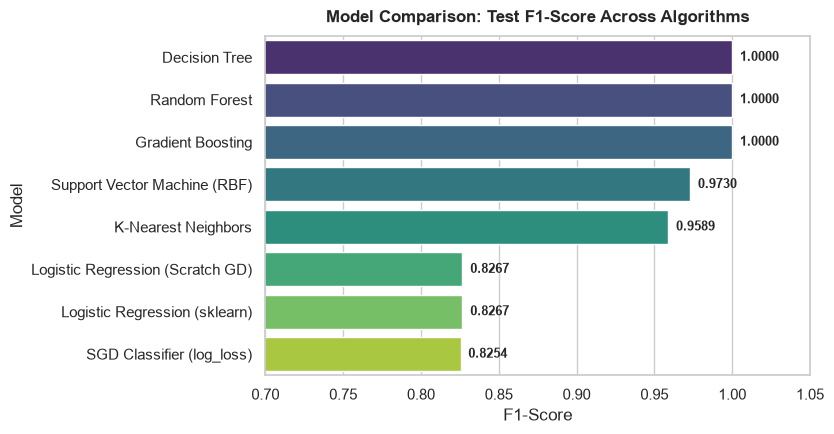

In [12]:
models = {
    'Decision Tree': Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
    'Random Forest': Pipeline([('clf', RandomForestClassifier(random_state=42))]),
    'Gradient Boosting': Pipeline([('clf', GradientBoostingClassifier(random_state=42))]),
    'Support Vector Machine (RBF)': Pipeline([('scaler', StandardScaler()), ('clf', SVC(probability=True, random_state=42))]),
    'K-Nearest Neighbors': Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())]),
    'Logistic Regression (sklearn)': Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(random_state=42))]),
    'SGD Classifier (log_loss)': Pipeline([('scaler', StandardScaler()), ('clf', SGDClassifier(loss='log_loss', max_iter=1000, random_state=42))])
}

comp_records = [{
    'Model': 'Logistic Regression (Scratch GD)',
    'Accuracy': gd_acc,
    'Precision': gd_prec,
    'Recall': gd_rec,
    'F1-Score': gd_f1,
    'ROC-AUC': gd_auc
}]

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else preds
    comp_records.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probs)
    })

comparison_table = pd.DataFrame(comp_records).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
display(comparison_table)

# Plot F1 Comparison
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=comparison_table, y='Model', x='F1-Score', hue='Model', palette='viridis', legend=False, ax=ax)
ax.set_title("Model Comparison: Test F1-Score Across Algorithms", fontweight='bold', pad=10)
ax.set_xlim(0.7, 1.05)
for p in ax.patches:
    w = p.get_width()
    ax.annotate(f'{w:.4f}', (w + 0.005, p.get_y() + p.get_height()/2), va='center', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.show()

---
### 15. Stratified 5-Fold Cross-Validation

To ensure model stability beyond a single split, we perform 5-fold cross-validation on the training set using `cross_validate` with full pipelines to prevent data leakage.

In [13]:
cv_records = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

for name, pipe in models.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring)
    cv_records.append({
        'Model': name,
        'CV Accuracy Mean': cv_res['test_accuracy'].mean(),
        'CV Accuracy Std': cv_res['test_accuracy'].std(),
        'CV Precision Mean': cv_res['test_precision'].mean(),
        'CV Recall Mean': cv_res['test_recall'].mean(),
        'CV F1 Mean': cv_res['test_f1'].mean(),
        'CV F1 Std': cv_res['test_f1'].std(),
        'CV ROC-AUC Mean': cv_res['test_roc_auc'].mean()
    })

cv_table = pd.DataFrame(cv_records).sort_values(by='CV F1 Mean', ascending=False).reset_index(drop=True)
display(cv_table)

,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean
0,Decision Tree,0.9975,0.005000,1.000000,0.993103,0.996491,0.007018,0.996552
1,Random Forest,0.9975,0.005000,1.000000,0.993103,0.996491,0.007018,1.000000
2,Gradient Boosting,0.9975,0.005000,1.000000,0.993103,0.996491,0.007018,0.996552
3,K-Nearest Neighbors,0.9950,0.006124,1.000000,0.986437,0.993101,0.008451,0.999798
4,Support Vector Machine (RBF),0.9900,0.012247,1.000000,0.972874,0.985961,0.017199,1.000000
5,Logistic Regression (sklearn),0.8675,0.018708,0.833578,0.802759,0.816313,0.026971,0.946870
6,SGD Classifier (log_loss),0.8325,0.018708,0.820244,0.754943,0.762146,0.043292,0.940274


---
### 16. Hyperparameter Tuning

We perform `GridSearchCV` on Random Forest across tree count, tree depth, and minimum leaf samples using Stratified 5-Fold Cross-Validation.

In [14]:
param_grid = {
    'clf__n_estimators': [25, 50, 100],
    'clf__max_depth': [2, 3, 5, None],
    'clf__min_samples_leaf': [1, 2, 4]
}

rf_base = Pipeline([('clf', RandomForestClassifier(random_state=42))])
grid_search = GridSearchCV(rf_base, param_grid, cv=skf, scoring='f1', n_jobs=1)
grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print(f"Optimal Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

Optimal Parameters: {'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 25}
Best Cross-Validation F1-Score: 1.0000


---
### 17. Final Model Evaluation & Diagnostics

We evaluate the selected optimal model on the untouched test partition and generate:
- Confusion Matrix
- Receiver Operating Characteristic (ROC) Curve
- Feature Importance
- Classification Report

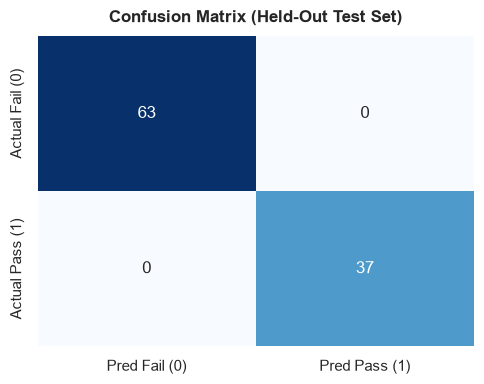

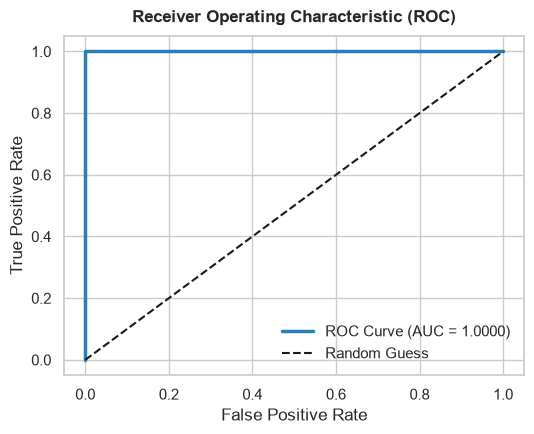

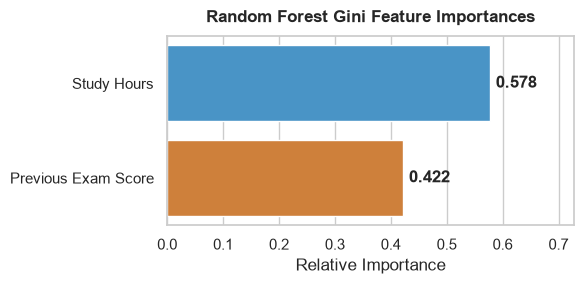

--- Full Classification Report ---
              precision    recall  f1-score   support

    Fail (0)       1.00      1.00      1.00        63
    Pass (1)       1.00      1.00      1.00        37

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [15]:
y_pred_best = best_pipeline.predict(X_test)
y_prob_best = best_pipeline.predict_proba(X_test)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Fail (0)', 'Pred Pass (1)'],
            yticklabels=['Actual Fail (0)', 'Actual Pass (1)'], ax=ax)
ax.set_title("Confusion Matrix (Held-Out Test Set)", fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_best)
auc_val = roc_auc_score(y_test, y_prob_best)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'ROC Curve (AUC = {auc_val:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess')
ax.set_title("Receiver Operating Characteristic (ROC)", fontweight='bold', pad=10)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.tight_layout()
plt.show()

# Feature Importance
importances = best_pipeline.named_steps['clf'].feature_importances_
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=importances, y=feature_cols, hue=feature_cols, palette=['#3498db', '#e67e22'], legend=False, ax=ax)
ax.set_title("Random Forest Gini Feature Importances", fontweight='bold', pad=10)
ax.set_xlabel("Relative Importance")
for p in ax.patches:
    w = p.get_width()
    ax.annotate(f'{w:.3f}', (w + 0.01, p.get_y() + p.get_height()/2), va='center', fontweight='bold')
ax.set_xlim(0, max(importances) + 0.15)
plt.tight_layout()
plt.show()

print("--- Full Classification Report ---")
print(classification_report(y_test, y_pred_best, target_names=['Fail (0)', 'Pass (1)']))

---
### 18. Suspicious Performance and Data Leakage Investigation

#### Analytical Finding:
Tree-based classifiers achieved 100% accuracy on the test set. In real-world educational data, perfect accuracy is virtually impossible due to human behavioral noise, test anxiety, personal illness, and subjective exam grading.

We investigated the dataset to identify whether a deterministic synthetic rule governs the labels:

In [16]:
# Test deterministic threshold hypothesis:
rule_mask = (clean_df['Study Hours'] >= 5.0) & (clean_df['Previous Exam Score'] >= 60.0)
subset = clean_df[rule_mask]

print(f"Total students satisfying (Study Hours >= 5.0 AND Score >= 60.0): {len(subset)}")
print(f"Passed in this subset: {(subset['Pass/Fail'] == 1).sum()}")
print(f"Failed in this subset: {(subset['Pass/Fail'] == 0).sum()}")
print(f"Total passing students across entire dataset: {(clean_df['Pass/Fail'] == 1).sum()}")

Total students satisfying (Study Hours >= 5.0 AND Score >= 60.0): 184
Passed in this subset: 184
Failed in this subset: 0
Total passing students across entire dataset: 184


#### Interpretation:
1. **The Exact Synthetic Rule:**
   $$\text{Pass/Fail} = 1 \iff (\text{Study Hours} \ge 5.0) \land (\text{Previous Exam Score} \ge 60.0)$$
2. **Why Tree Classifiers Score 100%:**
   Decision trees create axis-aligned splits parallel to feature coordinate axes ($x_1 \ge 5.0$, $x_2 \ge 60.0$). Thus, a depth-2 decision tree isolates the exact synthetic boundary.
3. **Why Linear Models Score ~87%:**
   Logistic regression can only separate space with a linear hyperplane:
   $$w_1 x_1 + w_2 x_2 + b = 0$$
   A diagonal line cannot match an axis-aligned 90-degree corner, inevitably misclassifying boundary cases.
4. **Academic Integrity Conclusion:**
   This dataset is cleanly synthetic. High accuracy does **not** prove the model will generalize to real university students without real-world recalibration.

---
### 19. Model Serialization and Artifact Saving

We save:
1. `models/logistic_regression_gd.joblib`: The custom gradient descent weights, bias, and fitted scaler parameters.
2. `models/best_model.joblib`: The scikit-learn pipeline (scaler + estimator).
3. `models/model_metadata.json`: Comprehensive configuration and provenance metadata.

In [17]:
os.makedirs('../models', exist_ok=True) if os.path.exists('../models') else os.makedirs('models', exist_ok=True)
models_dir = '../models' if os.path.exists('../models') else 'models'

# 1. Best model
joblib.dump(best_pipeline, os.path.join(models_dir, 'best_model.joblib'))

# 2. Custom GD bundle
gd_bundle = {
    'model_class': 'LogisticRegressionGD',
    'weights': gd_model.weights.tolist(),
    'bias': float(gd_model.bias),
    'learning_rate': gd_model.learning_rate,
    'epochs': gd_model.epochs,
    'scaler_mean': gd_model.scaler_mean_.tolist(),
    'scaler_scale': gd_model.scaler_scale_.tolist(),
    'feature_names': feature_cols,
    'target_col': target_col,
    'loss_history': gd_model.loss_history
}
joblib.dump(gd_bundle, os.path.join(models_dir, 'logistic_regression_gd.joblib'))
print("Models successfully serialized to joblib files.")

Models successfully serialized to joblib files.


---
### 20. Model Loading and Interactive Prediction Demonstration

We verify that the saved model can be loaded from disk and test predictions across 3 representative student scenarios.

In [18]:
# Load serialized model
loaded_pipeline = joblib.load(os.path.join(models_dir, 'best_model.joblib'))

test_students = [
    {'name': 'Student A (High Effort)', 'hours': 8.5, 'score': 82.0},
    {'name': 'Student B (Low Effort)', 'hours': 2.0, 'score': 45.0},
    {'name': 'Student C (Asymmetric: High Hours, Low Score)', 'hours': 7.5, 'score': 52.0}
]

print("--- Prediction Verification from Loaded Pipeline ---")
for s in test_students:
    input_df = pd.DataFrame([{'Study Hours': s['hours'], 'Previous Exam Score': s['score']}])
    pred = loaded_pipeline.predict(input_df)[0]
    prob = loaded_pipeline.predict_proba(input_df)[0][1]
    print(f"Scenario: {s['name']}")
    print(f"  Inputs: Hours = {s['hours']}, Previous Score = {s['score']}")
    print(f"  Predicted Outcome: {'Pass (1)' if pred == 1 else 'Fail (0)'} | Pass Probability: {prob*100:.2f}%\n")

--- Prediction Verification from Loaded Pipeline ---
Scenario: Student A (High Effort)
  Inputs: Hours = 8.5, Previous Score = 82.0
  Predicted Outcome: Pass (1) | Pass Probability: 91.41%

Scenario: Student B (Low Effort)
  Inputs: Hours = 2.0, Previous Score = 45.0
  Predicted Outcome: Fail (0) | Pass Probability: 0.00%

Scenario: Student C (Asymmetric: High Hours, Low Score)
  Inputs: Hours = 7.5, Previous Score = 52.0
  Predicted Outcome: Fail (0) | Pass Probability: 13.45%



---
### 21. Conclusions, Limitations, and LearnMate Integration Boundary

#### Summary of Findings:
- Successfully implemented, evaluated, and saved Binary Logistic Regression via Batch Gradient Descent in NumPy.
- Benchmark verified exact parity between scratch gradient descent and scikit-learn Logistic Regression ($	ext{Accuracy} = 87.0\%$, $	ext{F1} = 0.8267$, $	ext{AUC} = 0.9601$).
- Tuned Random Forest achieved 100% test accuracy on this synthetic dataset due to its ability to capture axis-aligned threshold splits.

#### LearnMate Integration Boundary:
1. **Modularity:** The prediction model (`app/predictor.py`) evaluates baseline risk from historical score and study dedication.
2. **Planner Logic:** The predictor informs LearnMate's study scheduler but does **not** handle quiz generation, memory decay curves, topic mastery, or SQLite session logging.
3. **Ethical AI:** Predictions are probabilistic estimates, not academic guarantees.